# Conventional Avocado Price Prediction and Forecasting
## Preisvorhersage und Prognose für konventionelle Avocados

Dieses Notebook entwickelt einen zeitbasierten Machine-Learning-Workflow zur
Vorhersage der Preise konventioneller Avocados. Die Analyse konzentriert sich
auf **San Francisco** und verwendet wöchentliche Beobachtungen von 2015 bis 2020.

Der Workflow besteht aus folgenden Schritten:

1. Laden und Auswahl der Daten,
2. Erzeugung einer regelmäßigen wöchentlichen Zeitreihe,
3. Interpolation fehlender Wochen,
4. Erstellung verzögerter Preis- und Volumenmerkmale,
5. Hinzufügen saisonaler Informationen,
6. zeitbewusste Kreuzvalidierung,
7. Vergleich mehrerer Machine-Learning-Modelle,
8. Optimierung der Modell-Hyperparameter,
9. Bewertung der Modelle im Hold-out-Zeitraum 2020 und
10. rekursive Prognose der Avocadopreise von Dezember 2020 bis Dezember 2021.

Die Zielvariable ist `average_price`.

In [1]:
# ============================================================
# CONVENTIONAL AVOCADO PRICE PREDICTION
# AND DEC 2020 -> DEC 2021 FORECAST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)



## 1. Laden und erste Untersuchung der Daten
Der vollständige Avocado-Datensatz wird geladen und die Spalte `date` in eine
Pandas-Datetime-Variable umgewandelt.

Der Datensatz enthält **33.045 Beobachtungen und 13 Variablen**. Zu diesen
Variablen gehören der durchschnittliche Avocadopreis, verschiedene
Verkaufsvolumina, der Avocadotyp, das Jahr und die geografische Region.

In diesem Schritt wird der ursprüngliche Datensatz zunächst untersucht, bevor
eine Filterung oder ein Feature Engineering durchgeführt wird.

In [2]:


# LOAD DATA

dataset = pd.read_csv("avocado-updated-2020.csv")

dataset["date"] = pd.to_datetime(dataset["date"], errors="coerce")

print("Original shape:", dataset.shape)
print(dataset.head())

print("\nColumns:")
print(dataset.columns.tolist())



Original shape: (33045, 13)
        date  average_price  total_volume       4046       4225      4770  \
0 2015-01-04           1.22      40873.28    2819.50   28287.42     49.90   
1 2015-01-04           1.79       1373.95      57.42     153.88      0.00   
2 2015-01-04           1.00     435021.49  364302.39   23821.16     82.15   
3 2015-01-04           1.76       3846.69    1500.15     938.35      0.00   
4 2015-01-04           1.08     788025.06   53987.31  552906.04  39995.03   

   total_bags  small_bags  large_bags  xlarge_bags          type  year  \
0     9716.46     9186.93      529.53          0.0  conventional  2015   
1     1162.65     1162.65        0.00          0.0       organic  2015   
2    46815.79    16707.15    30108.64          0.0  conventional  2015   
3     1408.19     1071.35      336.84          0.0       organic  2015   
4   141136.68   137146.07     3990.61          0.0  conventional  2015   

              geography  
0                Albany  
1           

## 2. Auswahl der konventionellen Avocado-Zeitreihe für San Francisco
Für die detaillierte Vorhersage wird der Datensatz auf Beobachtungen aus
**San Francisco** mit dem Avocadotyp `conventional` beschränkt.

Dadurch entstehen **306 Beobachtungen**. Die Beobachtungen werden vor der
weiteren Zeitreihenverarbeitung chronologisch sortiert.

San Francisco wird als separate Prognose-Fallstudie behandelt, anstatt alle
geografischen Regionen in einem einzigen Modell zusammenzufassen.

In [3]:

#    San Francisco
SF_conventional = dataset[(dataset["geography"] == "San Francisco")    &    (dataset["type"] == "conventional")].copy()
SF_conventional = (SF_conventional.sort_values("date").reset_index(drop=True))
print("\nConventional San Francisco data:")
print(SF_conventional.shape)
print(    SF_conventional[["date","average_price","total_volume"]].head())



Conventional San Francisco data:
(306, 13)
        date  average_price  total_volume
0 2015-01-04           0.99     907795.89
1 2015-01-11           1.03     916450.76
2 2015-01-18           1.22     753746.51
3 2015-01-25           1.21     713523.24
4 2015-02-01           0.91    1352027.64


In [4]:

# CHECK MISSING VALUES
print("\nMissing values BEFORE weekly reindexing:")
print(SF_conventional[["average_price","total_volume"]].isna().sum())


Missing values BEFORE weekly reindexing:
average_price    0
total_volume     0
dtype: int64


## 3. Erzeugung einer regelmäßigen wöchentlichen Zeitreihe
Die ursprünglichen San-Francisco-Daten enthalten keine fehlenden Werte in
`average_price` oder `total_volume`. Die Datumswerte bilden jedoch keine
vollständig kontinuierliche wöchentliche Zeitreihe.

Daher werden die Beobachtungen auf ein regelmäßiges
**Sonntag-zu-Sonntag-Wochenraster (`W-SUN`)** neu indexiert.

Aus den ursprünglich 306 Beobachtungen entstehen **309 Wochenpositionen**.
Die zusätzlichen Positionen entsprechen Wochen, die im ursprünglichen
Datensatz nicht vorhanden waren.

Die durch die Neuindexierung entstandenen fehlenden Werte werden durch
**zeitbasierte Interpolation** ergänzt. Zusätzlich werden Forward- und
Backward-Filling als Randabsicherung verwendet.

Es werden zwei interpolierte Variablen erzeugt:

- `average_price_interp`
- `total_volume_interp`

Nach der Interpolation enthalten diese beiden Variablen keine fehlenden Werte.




In [5]:
#
SF_conventional = SF_conventional.set_index("date")
weekly_index = pd.date_range(start=SF_conventional.index.min(), end=SF_conventional.index.max(), freq="W-SUN")
SF_conventional_weekly = (SF_conventional.reindex(weekly_index))
SF_conventional_weekly.index.name = "date"
print("\nNumber of weekly observations:", len(SF_conventional_weekly))


Number of weekly observations: 309


## 4. Saisonale Merkmale

Avocadopreise können eine saisonale Komponente enthalten. Um die Position
jeder Beobachtung innerhalb eines Jahres zu beschreiben, wird die
ISO-Kalenderwoche bestimmt.

Anstatt die Kalenderwoche direkt als numerischen Wert zu verwenden, wird die
Saisonalität durch zwei zyklische Variablen dargestellt:

\[\sin\left(\frac{2\pi w}{52}\right)\]

und

\[\cos\left(\frac{2\pi w}{52}\right),\]

wobei \(w\) die Kalenderwoche des Jahres bezeichnet.

Durch die Sinus- und Kosinusdarstellung bleibt die zyklische Struktur des
Kalenders erhalten: Woche 52 und Woche 1 werden als benachbarte Zeitpunkte
behandelt und nicht als numerisch weit voneinander entfernt.

In [6]:
# INTERPOLATE MISSING VALUES
SF_conventional_weekly["average_price_interp"] = (SF_conventional_weekly["average_price"].interpolate(method="time"))
SF_conventional_weekly["total_volume_interp"] = (SF_conventional_weekly["total_volume"].interpolate(method="time"))
# Boundary protection
SF_conventional_weekly["average_price_interp"] = (SF_conventional_weekly["average_price_interp"].ffill().bfill())
SF_conventional_weekly["total_volume_interp"] = (SF_conventional_weekly["total_volume_interp"].ffill().bfill())
SF_conventional_weekly["type"] = "conventional"
SF_conventional_weekly["geography"] = "San Francisco"
print("\nMissing values AFTER interpolation:")
print(SF_conventional_weekly[["average_price_interp", "total_volume_interp"]].isna().sum())




Missing values AFTER interpolation:
average_price_interp    0
total_volume_interp     0
dtype: int64


In [7]:

# RESET INDEX
SF_conventional_weekly = (SF_conventional_weekly.reset_index())
SF_conventional_weekly["year"] = (SF_conventional_weekly["date"].dt.year)


In [8]:
# SEASONAL FEATURES
SF_conventional_weekly["week_of_year"] = (SF_conventional_weekly["date"].dt.isocalendar().week.astype(int))
SF_conventional_weekly["sin_year"] = np.sin( 2 * np.pi * SF_conventional_weekly["week_of_year"] / 52.0)
SF_conventional_weekly["cos_year"] = np.cos( 2 * np.pi * SF_conventional_weekly["week_of_year"] / 52.0)

In [9]:
# PRICE LAGS
SF_conventional_weekly["price_1week"] = (SF_conventional_weekly[ "average_price_interp"].shift(1))
SF_conventional_weekly["price_2week"] = (SF_conventional_weekly["average_price_interp"].shift(2))
SF_conventional_weekly["price_4week"] = (SF_conventional_weekly["average_price_interp"].shift(4))

In [10]:

# 9. VOLUME LAGS
SF_conventional_weekly["volume_1week"] = (SF_conventional_weekly["total_volume_interp"].shift(1))
SF_conventional_weekly["volume_2week"] = (SF_conventional_weekly["total_volume_interp"].shift(2))
SF_conventional_weekly["volume_4week"] = (SF_conventional_weekly["total_volume_interp"].shift(4))

In [11]:
# OPTIONAL PRICE CHANGE FEATURES
SF_conventional_weekly["price_change_1_2week"] = (SF_conventional_weekly["price_1week"] - SF_conventional_weekly["price_2week"])
SF_conventional_weekly["price_change_1_4week"] = (SF_conventional_weekly["price_1week"] - SF_conventional_weekly["price_4week"])


Final modeling data shape:
(305, 26)

Model period:
2015-02-01 00:00:00 to 2020-11-29 00:00:00


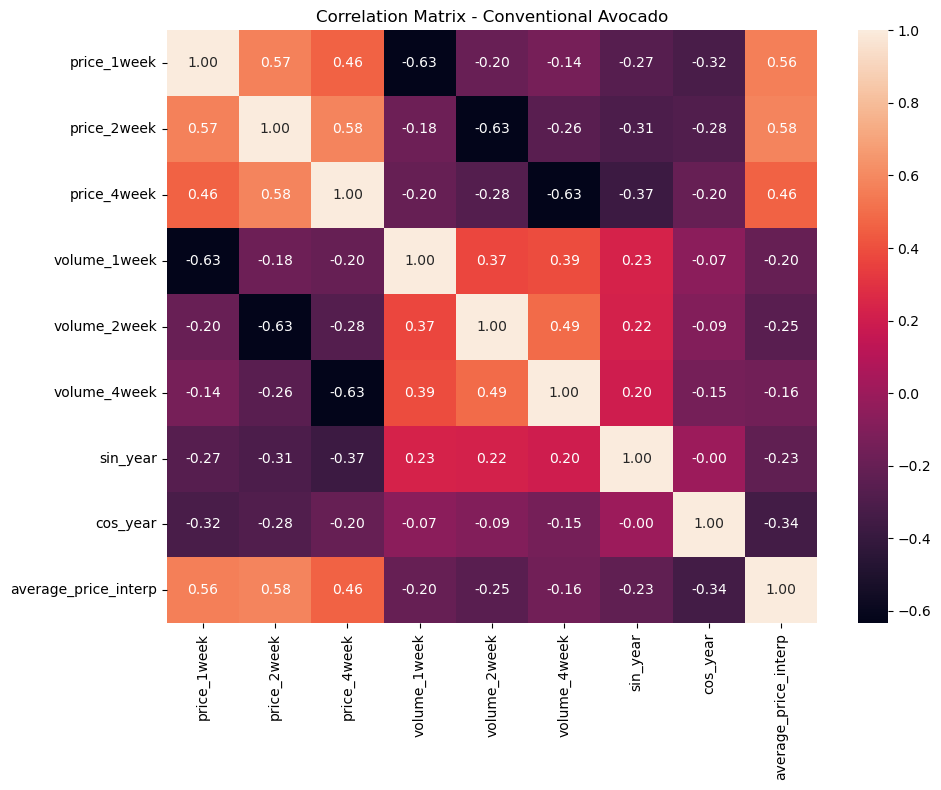

In [12]:
# FEATURE SETS
features_A = ["price_1week", "price_2week", "price_4week"]
features_B = ["price_1week", "price_2week", "price_4week",    "volume_1week",    "volume_2week",    "volume_4week"]
features_C = [    "price_1week",    "price_2week",    "price_4week",    "volume_1week",    "volume_2week",    "volume_4week",    "sin_year",    "cos_year"]
target = "average_price_interp"

# PREPARE MODELING DATA
model_data = SF_conventional_weekly.dropna(subset=features_C + [target]).copy()
model_data = (model_data.sort_values("date").reset_index(drop=True))
print("\nFinal modeling data shape:")
print(model_data.shape)
print("\nModel period:")
print(model_data["date"].min(), "to", model_data["date"].max())
#+CORRELATION MATRIX
correlation_columns = (features_C + [target])
plt.figure(figsize=(10, 8))
sns.heatmap(model_data[correlation_columns].corr(), annot=True, fmt=".2f")
plt.title("Correlation Matrix - Conventional Avocado")
plt.tight_layout()
plt.show()




Final modeling data shape:
(305, 26)

Model period:
2015-02-01 00:00:00 to 2020-11-29 00:00:00


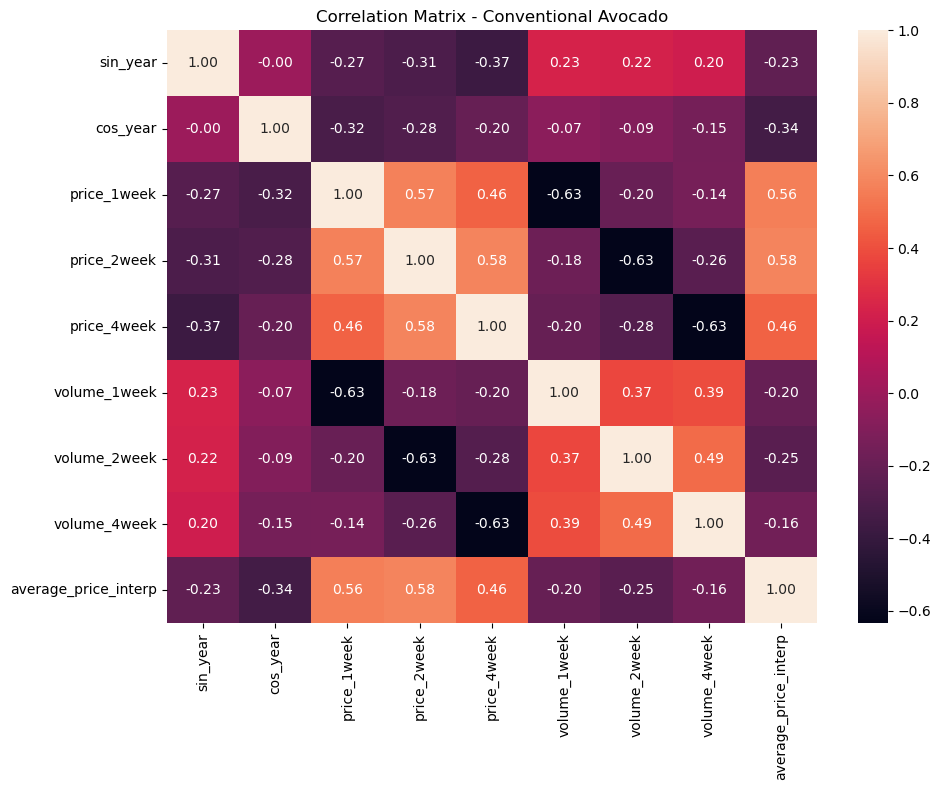

In [13]:
# FEATURE SETS
features_A = ["price_1week", "price_2week", "price_4week"]
features_B = ["sin_year", "cos_year", "price_1week", "price_2week", "price_4week",    "volume_1week",    "volume_2week",    "volume_4week"]
features_C = [    "price_1week",    "price_2week",    "price_4week",    "volume_1week",    "volume_2week",    "volume_4week",    "sin_year",    "cos_year"]
target = "average_price_interp"

# PREPARE MODELING DATA
model_data = SF_conventional_weekly.dropna(subset=features_B + [target]).copy()
model_data = (model_data.sort_values("date").reset_index(drop=True))
print("\nFinal modeling data shape:")
print(model_data.shape)
print("\nModel period:")
print(model_data["date"].min(), "to", model_data["date"].max())
#+CORRELATION MATRIX
correlation_columns = (features_B + [target])
plt.figure(figsize=(10, 8))
sns.heatmap(model_data[correlation_columns].corr(), annot=True, fmt=".2f")
plt.title("Correlation Matrix - Conventional Avocado")
plt.tight_layout()
plt.show()

In [14]:

# EXPANDING YEAR CROSS VALIDATION
years = sorted(model_data["year"].unique())
year_splits = []
for test_year in years[1:]:

    train_idx = model_data.index[model_data["year"] < test_year].to_numpy()
    test_idx = model_data.index[model_data["year"] == test_year].to_numpy()
    if (
        len(train_idx) == 0
        or len(test_idx) == 0
    ):
        continue
    year_splits.append((train_idx, test_idx))
print("\nYEAR-BASED CROSS VALIDATION:")
for i, (train_idx, test_idx) in enumerate( year_splits,    start=1):
    train_years = ( model_data        .loc[train_idx, "year"].unique())
    test_year = (model_data.loc[test_idx, "year"].unique())

    print(f"Fold {i}: "f"Train = {train_years} "f"--> Test = {test_year}"    )


YEAR-BASED CROSS VALIDATION:
Fold 1: Train = [2015] --> Test = [2016]
Fold 2: Train = [2015 2016] --> Test = [2017]
Fold 3: Train = [2015 2016 2017] --> Test = [2018]
Fold 4: Train = [2015 2016 2017 2018] --> Test = [2019]
Fold 5: Train = [2015 2016 2017 2018 2019] --> Test = [2020]


In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

In [16]:
# MODELS
models = {"Linear Regression": LinearRegression(), "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=5))]), "SVR": Pipeline([("scaler", StandardScaler()),
            ("model", SVR(kernel="sigmoid", C=1.0, epsilon=0.01, gamma=0.01))]),    "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=5, min_samples_leaf=1, min_samples_split=2, random_state=42, n_jobs=-1)}

In [17]:
from sklearn.model_selection import GridSearchCV

knn_grid = {"model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]}

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

X = model_data[features_C]
y = model_data[target]

grid_knn.fit(X, y)
best_knn = grid_knn.best_estimator_
print("Best KNN parameters:")
print(grid_knn.best_params_)

print("Best KNN CV MAE:")
print(-grid_knn.best_score_)

Best KNN parameters:
{'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'uniform'}
Best KNN CV MAE:
0.18652510885341073


In [18]:
print("Features used:")
print(features_C)

print("\nTarget:")
print(target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features used:
['price_1week', 'price_2week', 'price_4week', 'volume_1week', 'volume_2week', 'volume_4week', 'sin_year', 'cos_year']

Target:
average_price_interp

X shape: (305, 8)
y shape: (305,)


In [19]:
svr_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__epsilon": [0.01, 0.05, 0.1, 0.2],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(kernel="rbf"))
])

grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_svr.fit(X, y)
best_svr = grid_svr.best_estimator_
print(grid_svr.best_params_)
print(-grid_svr.best_score_)

{'model__C': 1, 'model__epsilon': 0.01, 'model__gamma': 0.01}
0.17325484883570474


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV


# ============================================================
# SVR PIPELINE
# ============================================================

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR())
])


# ============================================================
# DIFFERENT KERNELS + THEIR PARAMETERS
# ============================================================

svr_grid = [

    # --------------------------------------------------------
    # LINEAR KERNEL
    # gamma and degree are not needed
    # --------------------------------------------------------
    {
        "model__kernel": ["linear"],
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2]
    },


    # --------------------------------------------------------
    # RBF KERNEL
    # --------------------------------------------------------
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    },


    # --------------------------------------------------------
    # POLYNOMIAL KERNEL
    # --------------------------------------------------------
    {
        "model__kernel": ["poly"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__degree": [2, 3, 4]
    },


    # --------------------------------------------------------
    # SIGMOID KERNEL
    # --------------------------------------------------------
    {
        "model__kernel": ["sigmoid"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.001, 0.01, 0.1]
    }
]


# ============================================================
# GRID SEARCH
# ============================================================

grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    return_train_score=True
)


grid_svr.fit(X, y)


# ============================================================
# BEST RESULT
# ============================================================

print("Best parameters:")
print(grid_svr.best_params_)

print("\nBest CV MAE:")
print(-grid_svr.best_score_)

best_svr = grid_svr.best_estimator_

Best parameters:
{'model__C': 10, 'model__epsilon': 0.01, 'model__gamma': 0.001, 'model__kernel': 'sigmoid'}

Best CV MAE:
0.17180176703803132


In [21]:
svr_results = pd.DataFrame(
    grid_svr.cv_results_
)

svr_results["MAE"] = (
    -svr_results["mean_test_score"]
)


kernel_summary = (
    svr_results
    .groupby("param_model__kernel")["MAE"]
    .min()
    .sort_values()
)

print(kernel_summary)

param_model__kernel
sigmoid    0.171802
linear     0.171839
rbf        0.172872
poly       0.197034
Name: MAE, dtype: float64


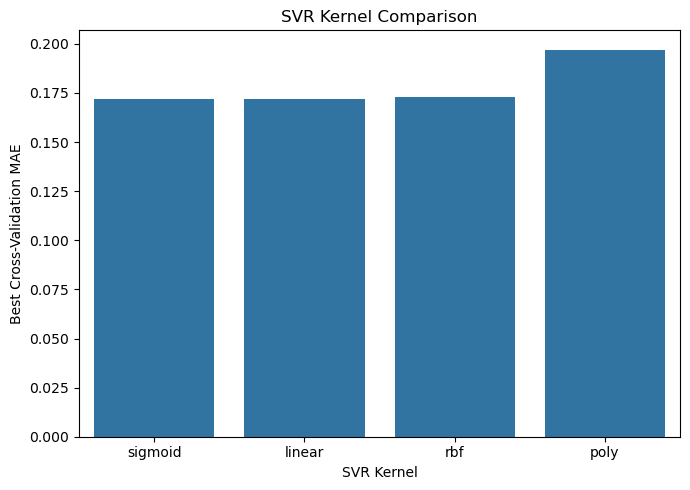

In [22]:
kernel_summary = (
    kernel_summary
    .reset_index()
)

kernel_summary.columns = [
    "Kernel",
    "Best_MAE"
]


plt.figure(figsize=(7, 5))

sns.barplot(
    data=kernel_summary,
    x="Kernel",
    y="Best_MAE"
)

plt.xlabel("SVR Kernel")
plt.ylabel("Best Cross-Validation MAE")

plt.title(
    "SVR Kernel Comparison"
)

plt.tight_layout()
plt.show()

In [23]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

In [24]:
grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_grid,
    cv=year_splits,
    scoring=scoring,
    refit="MAE",
    n_jobs=-1,
    return_train_score=True
)

grid_svr.fit(X, y)

,estimator,"Pipeline(step...del', SVR())])"
,param_grid,"[{'model__C': [0.01, 0.1, ...], 'model__epsilon': [0.01, 0.05, ...], 'model__kernel': ['linear']}, {'model__C': [0.1, 1, ...], 'model__epsilon': [0.01, 0.05, ...], 'model__gamma': ['scale', 0.001, ...], 'model__kernel': ['rbf']}, ...]"
,scoring,"{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,n_jobs,-1
,refit,'MAE'
,cv,"[(array([ 0, 1..., 45, 46, 47]), ...), (array([ 0, 1..., 97, 98, 99]), ...), ...]"
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,copy,True


In [25]:
svr_results = pd.DataFrame(
    grid_svr.cv_results_
)

svr_results["MAE"] = (
    -svr_results["mean_test_MAE"]
)

svr_results["RMSE"] = (
    -svr_results["mean_test_RMSE"]
)

svr_results["R2"] = (
    svr_results["mean_test_R2"]
)

In [26]:
best_kernel_results = (
    svr_results
    .sort_values("MAE")
    .groupby(
        "param_model__kernel",
        as_index=False
    )
    .first()
)


print(
    best_kernel_results[
        [
            "param_model__kernel",
            "param_model__C",
            "param_model__epsilon",
            "param_model__gamma",
            "param_model__degree",
            "MAE",
            "RMSE",
            "R2"
        ]
    ]
)

  param_model__kernel  param_model__C  param_model__epsilon  \
0              linear            0.01                  0.01   
1                poly           10.00                  0.01   
2                 rbf           10.00                  0.01   
3             sigmoid           10.00                  0.01   

  param_model__gamma  param_model__degree       MAE      RMSE        R2  
0               None                  NaN  0.171839  0.217600  0.263919  
1               0.01                  3.0  0.197034  0.244572  0.119200  
2              0.001                  NaN  0.172872  0.218315  0.258052  
3              0.001                  NaN  0.171802  0.217550  0.264235  


In [27]:
rf_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_rf.fit(X, y)
best_rf = grid_rf.best_estimator_
print(grid_rf.best_params_)
print(-grid_rf.best_score_)

{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
0.1745936082775894


In [28]:
models_tuned = {
    "Linear Regression": LinearRegression(),
    "KNN tuned": best_knn,
    "SVR tuned": best_svr,
    "Random Forest tuned": best_rf
}

In [29]:

# 1EVALUATION FUNCTIONS
def evaluate_model(model_name,    feature_set_name,    test_year,    y_true,    y_pred):

    return {"Feature_Set": feature_set_name, "Model": model_name, "Test_Year": test_year, 
        "MAE": mean_absolute_error( y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE":root_mean_squared_error(y_true, y_pred),
        "R2":r2_score( y_true, y_pred)}

In [30]:
# CROSS VALIDATION FUNCTION
def year_cross_validation(data, features, feature_set_name, model, model_name):

    results = []
    for fold, (train_idx, test_idx) in enumerate( year_splits, start=1):
        X_train = data.loc[train_idx, features]
        X_test = data.loc[test_idx,features]
        y_train = data.loc[train_idx, target]
        y_test = data.loc[test_idx, target]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        test_year = (data.loc[test_idx, "year"].iloc[0])
        result = evaluate_model(model_name, feature_set_name, test_year, y_test, y_pred)
        result["Fold"] = fold
        results.append(result)
    return pd.DataFrame(results)

In [31]:
#####´´FEATURE SETS
feature_sets = {"A: Price only": features_A, "B: Price + Volume": features_B, "C: Price + Volume + Seasonality": features_C}

In [32]:
#RUN CROSS VALIDATION#
all_results = []
for feature_set_name, features in feature_sets.items():
    for model_name, model in models.items():
        result = year_cross_validation(
            data=model_data,

            features=features,

            feature_set_name=feature_set_name,

            model=model,

            model_name=model_name
        )
        all_results.append(result)

all_results = pd.concat(all_results, ignore_index=True)
# SUMMARY
summary = (all_results.groupby(["Feature_Set", "Model"])[["MAE","MSE","RMSE","R2"]].mean().reset_index().sort_values("MAE"))
print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print(summary.to_string(index=False))



AVERAGE CROSS-VALIDATION PERFORMANCE
                    Feature_Set             Model      MAE      MSE     RMSE       R2
                  A: Price only               SVR 0.168649 0.046885 0.215792 0.269481
              B: Price + Volume               SVR 0.172061 0.047762 0.217572 0.263668
C: Price + Volume + Seasonality               SVR 0.172061 0.047762 0.217572 0.263668
C: Price + Volume + Seasonality     Random Forest 0.174594 0.053380 0.230015 0.193681
              B: Price + Volume     Random Forest 0.175075 0.053576 0.230516 0.188838
                  A: Price only Linear Regression 0.176888 0.047555 0.217276 0.260092
                  A: Price only     Random Forest 0.182413 0.054456 0.232039 0.187752
C: Price + Volume + Seasonality Linear Regression 0.184327 0.058268 0.238375 0.116233
              B: Price + Volume Linear Regression 0.184327 0.058268 0.238375 0.116233
              B: Price + Volume               KNN 0.189830 0.057585 0.239254 0.116208
C: Price + Volum

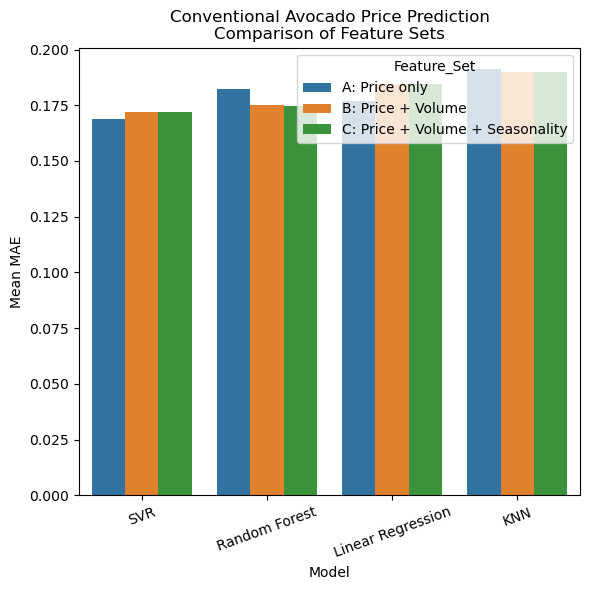

In [33]:
# MODEL COMPARISON PLOT
plt.figure(figsize=(6, 6))
sns.barplot(data=summary, x="Model",    y="MAE",    hue="Feature_Set")
plt.ylabel("Mean MAE")
plt.xlabel("Model")
plt.title("Conventional Avocado Price Prediction\n"    "Comparison of Feature Sets")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


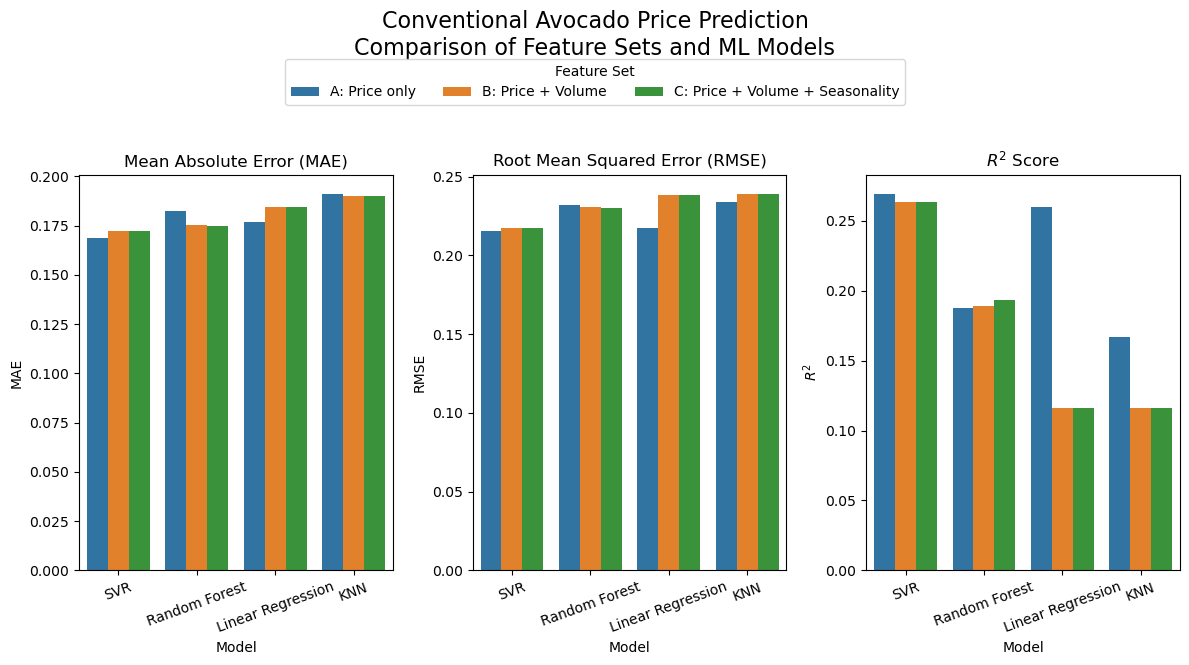

In [34]:

# MODEL COMPARISON: MAE, RMSE AND R2 TOGETHER
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
sns.barplot(data=summary, x="Model", y="MAE", hue="Feature_Set", ax=axes[0])
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=summary, x="Model", y="RMSE", hue="Feature_Set", ax=axes[1])
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=20)
sns.barplot(data=summary, x="Model", y="R2", hue="Feature_Set", ax=axes[2])
axes[2].set_title(r"$R^2$ Score")
axes[2].set_xlabel("Model")
axes[2].set_ylabel(r"$R^2$")
axes[2].tick_params(axis="x", rotation=20)
axes[0].get_legend().remove()
axes[1].get_legend().remove()
axes[2].get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Feature Set", loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=3)
fig.suptitle("Conventional Avocado Price Prediction\n" "Comparison of Feature Sets and ML Models", fontsize=16, y=1.10)
plt.tight_layout()
plt.savefig("conventional_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

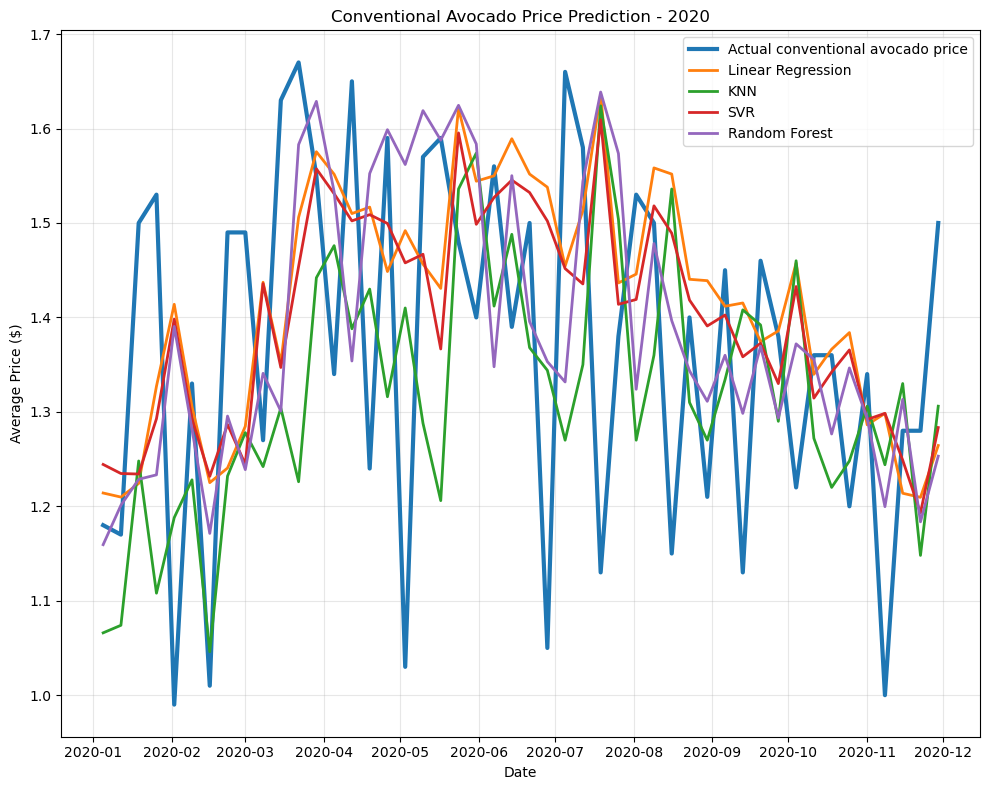

In [35]:
# TEST YEAR 2020
train_2020 = model_data[model_data["year"] < 2020].copy()
test_2020 = model_data[model_data["year"] == 2020].copy()
X_train_2020 = train_2020[features_C]
X_test_2020 = test_2020[features_C]
y_train_2020 = train_2020[target]
y_test_2020 = test_2020[target]
#TEST ALL FOUR METHODS ON 2020
predictions_2020 = {}
for model_name, model in models.items():
    model.fit(X_train_2020, y_train_2020)
    predictions_2020[model_name] = model.predict(X_test_2020)
# 24. 2020 ACTUAL VS DIFFERENT METHODS
plt.figure(figsize=(10, 8))
plt.plot(test_2020["date"],y_test_2020, linewidth=3, label="Actual conventional avocado price")
for model_name, pred in predictions_2020.items():
    plt.plot(test_2020["date"], pred, linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Average Price ($)")
plt.title("Conventional Avocado Price Prediction - 2020")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("conventional_avocado_prediction_2020_all_methods.png", dpi=300, bbox_inches="tight")
plt.show()



In [36]:
# METRICS FOR EACH METHOD IN 2020
results_2020 = []
for model_name, pred in predictions_2020.items():
    results_2020.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test_2020, pred),
        "RMSE": root_mean_squared_error(y_test_2020, pred),
        "R2": r2_score(y_test_2020, pred)})
results_2020 = pd.DataFrame(results_2020)
print(    "\n2020 MODEL PERFORMANCE:")
print(    results_2020.sort_values("MAE").to_string(index=False))


2020 MODEL PERFORMANCE:
            Model      MAE     RMSE        R2
              SVR 0.163117 0.203449 -0.142935
    Random Forest 0.164303 0.206937 -0.182465
Linear Regression 0.168350 0.213489 -0.258518
              KNN 0.193792 0.228301 -0.439213


In [37]:


# FUTURE FORECAST:
# DECEMBER 2020 -> DECEMBER 2021## 26. FORECAST DATES# 
forecast_start = pd.Timestamp("2020-12-06")
forecast_end = pd.Timestamp("2021-12-26")
future_dates = pd.date_range(start=forecast_start,    end=forecast_end,    freq="W-SUN")
print(    "\nForecast period:",    future_dates.min(),    "to",    future_dates.max())
#ONLY USE DATA BEFORE FORECAST START
historical_data = SF_conventional_weekly[SF_conventional_weekly["date"]    < forecast_start].copy()
historical_data = (    historical_data    .sort_values("date").reset_index(drop=True))
price_features = features_C
price_train = historical_data.dropna(subset=price_features + ["average_price_interp"]).copy()
X_price_train = price_train[price_features]
y_price_train = price_train["average_price_interp"]
# FUTURE VOLUME MODEL# Volume itself must also be forecast because future volume# is unknown.# 
volume_features = ["volume_1week",    "volume_2week",    "volume_4week",    "sin_year",    "cos_year"]
volume_train = historical_data.dropna(subset=volume_features + ["total_volume_interp"]).copy()
X_volume_train = volume_train[volume_features]
y_volume_train = volume_train["total_volume_interp"]
volume_model = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
volume_model.fit(X_volume_train, y_volume_train)
# RECURSIVE VOLUME FORECAST
volume_history = list(historical_data["total_volume_interp"].values)
future_volume = []
for date in future_dates:
    week = date.isocalendar().week
    sin_year = np.sin(2 * np.pi * week / 52.0)
    cos_year = np.cos(2 * np.pi * week / 52.0)
    volume_1week = volume_history[-1]
    volume_2week = volume_history[-2]
    volume_4week = volume_history[-4]
    X_future_volume = pd.DataFrame([[volume_1week, volume_2week, volume_4week, sin_year, cos_year]], columns=volume_features)
    predicted_volume = volume_model.predict(X_future_volume)[0]
    predicted_volume = max(predicted_volume, 0)
    future_volume.append(predicted_volume)
    volume_history.append(predicted_volume)
# RECURSIVE PRICE FORECAST FUNCTION# 
def recursive_price_forecast(model,    historical_data,    future_dates,    future_volume):
    trained_model = clone(model)
    trained_model.fit(X_price_train, y_price_train    )
    price_history = list(historical_data["average_price_interp"].values)
    volume_history = list(historical_data["total_volume_interp"].values)
    predictions = []
    for i, date in enumerate(future_dates):
        week = date.isocalendar().week
        sin_year = np.sin(2 * np.pi * week / 52.0)
        cos_year = np.cos(2 * np.pi * week / 52.0)
        # PRICE LAGS
        price_1week = price_history[-1]
        price_2week = price_history[-2]
        price_4week = price_history[-4]
        # VOLUME LAGS
        volume_1week = volume_history[-1]
        volume_2week = volume_history[-2]
        volume_4week = volume_history[-4]
        X_future = pd.DataFrame([[price_1week, price_2week, price_4week, volume_1week, volume_2week, volume_4week, sin_year, cos_year]], columns=price_features)
        predicted_price = (trained_model.predict(X_future)[0])
        predictions.append(predicted_price)
        # Recursive update
        price_history.append(predicted_price)
        volume_history.append(future_volume[i])
    return np.array(predictions)



Forecast period: 2020-12-06 00:00:00 to 2021-12-26 00:00:00


In [38]:
## FORECAST WITH ALL METHODS#++++
future_predictions = {}
for model_name, model in models.items():
    print(f"Forecasting with {model_name}...")
    future_predictions[model_name] = recursive_price_forecast(
        model=model,
        historical_data=
            historical_data,
        future_dates=
            future_dates,
        future_volume=
            future_volume
    )


Forecasting with Linear Regression...
Forecasting with KNN...
Forecasting with SVR...
Forecasting with Random Forest...


In [39]:

# FUTURE DATAFRAME# 
forecast_df = pd.DataFrame({
    "date":
        future_dates
})
for model_name in future_predictions:
    forecast_df[
        model_name
    ] = future_predictions[
        model_name
    ]


forecast_df[
    "Predicted Volume"
] = future_volume


print(
    "\nFuture conventional avocado forecast:"
)

print(
    forecast_df.head(10)
)




Future conventional avocado forecast:
        date  Linear Regression    KNN       SVR  Random Forest  \
0 2020-12-06           1.295937  1.218  1.289349       1.206857   
1 2020-12-13           1.343852  1.234  1.356811       1.198764   
2 2020-12-20           1.309196  1.294  1.309213       1.204481   
3 2020-12-27           1.342066  1.296  1.352831       1.242932   
4 2021-01-03           1.302169  1.198  1.310740       1.196360   
5 2021-01-10           1.316909  1.270  1.330975       1.231522   
6 2021-01-17           1.299689  1.188  1.313689       1.218103   
7 2021-01-24           1.329823  1.294  1.333940       1.231487   
8 2021-01-31           1.317394  1.202  1.321358       1.246314   
9 2021-02-07           1.319579  1.140  1.328856       1.205112   

   Predicted Volume  
0      8.916812e+05  
1      9.010977e+05  
2      9.688900e+05  
3      9.148158e+05  
4      9.980141e+05  
5      9.849332e+05  
6      1.112081e+06  
7      1.078181e+06  
8      1.056421e+06  
9  

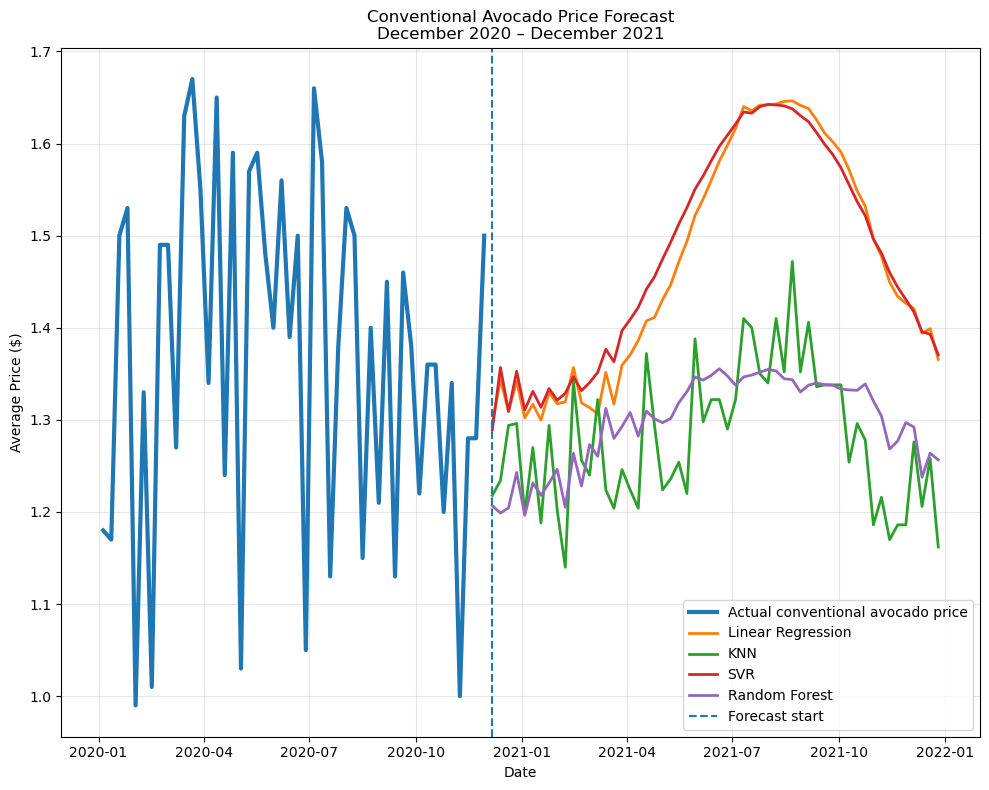

In [40]:
# HISTORICAL + FUTURE FORECAST

plt.figure(figsize=(10, 8))
plot_history = historical_data[
    historical_data["date"]
    >= pd.Timestamp("2020-01-01")
]
plt.plot(plot_history["date"], plot_history["average_price_interp"], linewidth=3, label="Actual conventional avocado price")
for model_name in models.keys():
    plt.plot(forecast_df["date"],forecast_df[model_name], linewidth=2, label=model_name)
plt.axvline(forecast_start,linestyle="--", linewidth=1.5, label="Forecast start")
plt.xlabel("Date")
plt.ylabel("Average Price ($)")
plt.title("Conventional Avocado Price Forecast\n" "December 2020 – December 2021")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("conventional_avocado_forecast_2021_all_models.png", dpi=300, bbox_inches="tight")
plt.show()


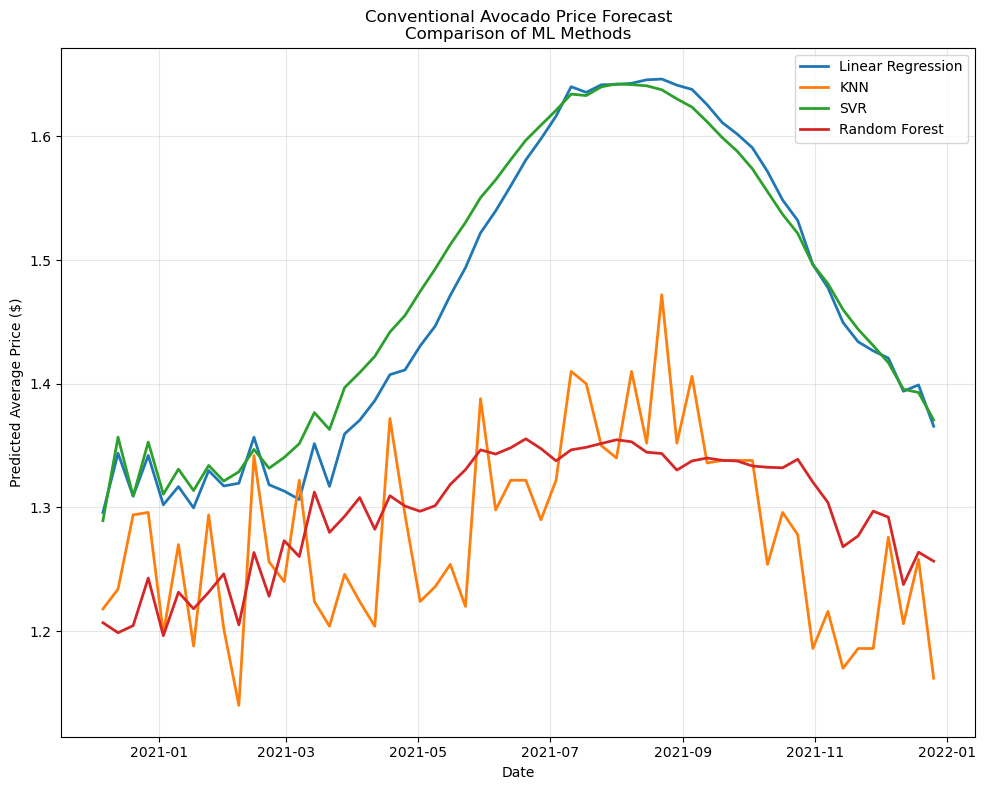

In [41]:
 
# FORECAST-ONLY COMPARISON
# 
plt.figure(figsize=(10, 8))
for model_name in models.keys():
    plt.plot(forecast_df["date"], forecast_df[model_name],linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Predicted Average Price ($)")
plt.title("Conventional Avocado Price Forecast\n" "Comparison of ML Methods")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("conventional_avocado_2021_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


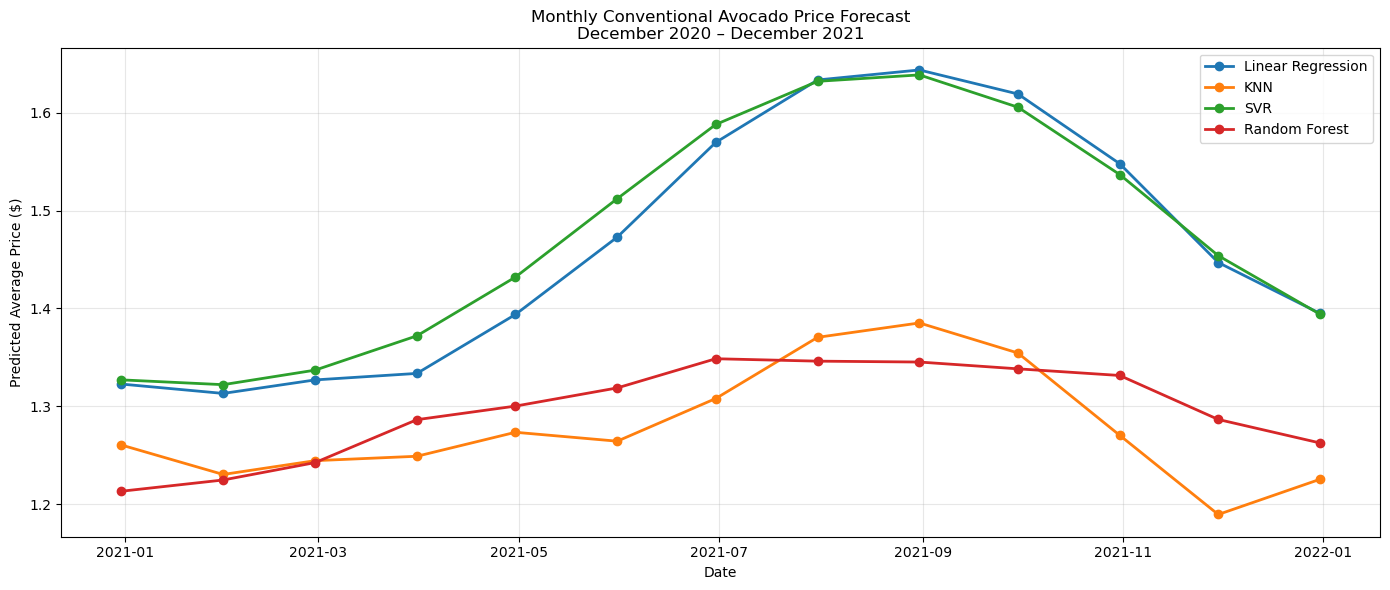

In [42]:
# MONTHLY FORECAST
forecast_monthly = (forecast_df.set_index("date") [list(models.keys())]
    .resample("ME")
    .mean()
    .reset_index()
)
plt.figure(figsize=(14, 6))
for model_name in models.keys():
    plt.plot(forecast_monthly["date"], forecast_monthly[model_name], marker="o", linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Predicted Average Price ($)")
plt.title("Monthly Conventional Avocado Price Forecast\n" "December 2020 – December 2021")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("conventional_avocado_2021_monthly_forecast.png", dpi=300, bbox_inches="tight")
plt.show()